# Chapter 9: Text Processing and Multiclass Classification

## 1. Ringkasan Bab
Pemrosesan teks (*Natural Language Processing* dasar) memerlukan tahapan konversi data tidak terstruktur menjadi representasi numerik matriks yang dapat dipahami algoritma machine learning. Bab ini membahas alur kerja lengkap pemrosesan teks hingga pemodelan klasifikasi multikelas:
- **Teknik Vektorisasi Teks**: Pendekatan frekuensi kemunculan token (`CountVectorizer`) dan pembobotan kepentingan kata (`TfidfVectorizer`).
- **Ekstraksi Fitur Teks Lanjutan**: Penggunaan kombinasi pasangan kata (*n-grams*), penghapusan kata umum (*stop words*), serta pembatasan frekuensi dokumen (`sublinear_tf`, `min_df`).
- **Pemodelan Klasifikasi Teks**: Pemanfaatan algoritma probabilistik Multinomial Naive Bayes (`MultinomialNB`) yang efisien dan tangguh pada ruang fitur teks yang jarang (*sparse*).
- **Strategi Multikelas**: Penanganan klasifikasi lebih dari dua kelas melalui pendekatan bawaan maupun integrasi strategi *One-vs-Rest* (OvR).
- **Pipeline Teks End-to-End**: Enkapsulasi vektorisasi dan estimasi klasifikasi dalam satu objek alur terpadu untuk pengujian teks baru secara instan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings

np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Modul dan dependensi Chapter 9 berhasil dimuat.")

Modul dan dependensi Chapter 9 berhasil dimuat.


## 2. Vektorisasi Teks: Bag-of-Words vs TF-IDF

Komputer memproses teks melalui representasi ruang vektor (*Vector Space Model*):

1. **Bag-of-Words (`CountVectorizer`)**:
   Menghitung frekuensi kemunculan kata pada tiap dokumen. Kekurangannya, kata-kata yang terlalu sering muncul (seperti kata penghubung) akan mendominasi bobot fitur.

2. **Term Frequency-Inverse Document Frequency (`TfidfVectorizer`)**:
   Menyeimbangkan frekuensi kata dalam dokumen ($TF$) dengan tingkat kelangkaan kata tersebut di seluruh korpus dokumen ($IDF$):
   $$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$
   $$\text{IDF}(t, D) = \log\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$
   Kata yang muncul di hampir semua dokumen akan menerima nilai penalti bobot mendekati nol.

In [4]:
# Demonstrasi Dasar Vektorisasi Korpus Sederhana
sample_corpus = [
    "Machine learning and data science are transforming the world.",
    "Natural language processing enables computers to understand text.",
    "Text vectorization transforms raw text into numerical feature vectors.",
    "Machine learning models require numerical feature vectors for training."
]

# 1. CountVectorizer
count_vec = CountVectorizer(stop_words='english')
X_count = count_vec.fit_transform(sample_corpus)

# 2. TfidfVectorizer dengan n-gram (unigram + bigram)
tfidf_vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
X_tfidf = tfidf_vec.fit_transform(sample_corpus)

print(f"Jumlah Fitur CountVectorizer (Unigram)     : {X_count.shape[1]}")
print(f"Jumlah Fitur TfidfVectorizer (Unigram+Bigram): {X_tfidf.shape[1]}")
print("\nContoh Fitur TF-IDF Teratas:")
print(tfidf_vec.get_feature_names_out()[:10])

Jumlah Fitur CountVectorizer (Unigram)     : 22
Jumlah Fitur TfidfVectorizer (Unigram+Bigram): 44

Contoh Fitur TF-IDF Teratas:
['computers' 'computers understand' 'data' 'data science' 'enables'
 'enables computers' 'feature' 'feature vectors' 'language'
 'language processing']


## 3. Dataset dan Pemodelan Klasifikasi Teks

Untuk evaluasi skala riil, digunakan subset dari dataset **20 Newsgroups** yang terdiri dari 4 kategori topik dokumen:
- `rec.autos`
- `rec.sport.baseball`
- `sci.space`
- `talk.religion.misc`

Algoritma yang digunakan adalah **Multinomial Naive Bayes**, yang mengasumsikan independensi kondisional antar-kata dan memodelkan probabilitas keanggotaan kelas $c$ berdasarkan perkalian probabilitas kemunculan kata $w_i$:
$$P(c \mid \mathbf{w}) \propto P(c) \prod_{i=1}^{n} P(w_i \mid c)$$

In [3]:
# Memuat Subset Data 20 Newsgroups (Train & Test Terpisah)
categories = ['rec.autos', 'rec.sport.baseball', 'sci.space', 'talk.religion.misc']

newsgroups_train = fetch_20newsgroups(
    subset='train', categories=categories, shuffle=True, random_state=2024,
    remove=('headers', 'footers', 'quotes')
)
newsgroups_test = fetch_20newsgroups(
    subset='test', categories=categories, shuffle=True, random_state=2024,
    remove=('headers', 'footers', 'quotes')
)

X_train_text = newsgroups_train.data
y_train_text = newsgroups_train.target
X_test_text = newsgroups_test.data
y_test_text = newsgroups_test.target
target_names = newsgroups_train.target_names

print(f"Jumlah dokumen latih : {len(X_train_text)}")
print(f"Jumlah dokumen uji   : {len(X_test_text)}")
print("Daftar Kategori Topik:", target_names)

Jumlah dokumen latih : 2161
Jumlah dokumen uji   : 1438
Daftar Kategori Topik: ['rec.autos', 'rec.sport.baseball', 'sci.space', 'talk.religion.misc']


In [6]:
# Membangun Pipeline Teks End-to-End: TF-IDF -> Multinomial Naive Bayes
text_clf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        min_df=3,
        sublinear_tf=True
    )),
    ('clf', MultinomialNB(alpha=0.1))
])

# Melatih Pipeline pada Data Teks Latih
text_clf_pipeline.fit(X_train_text, y_train_text)

# Evaluasi Prediksi pada Data Uji
y_pred_text = text_clf_pipeline.predict(X_test_text)
acc_text = accuracy_score(y_test_text, y_pred_text)

print(f"Akurasi Model Klasifikasi Teks: {acc_text:.4f} ({acc_text*100:.2f}%)")

Akurasi Model Klasifikasi Teks: 0.8707 (87.07%)


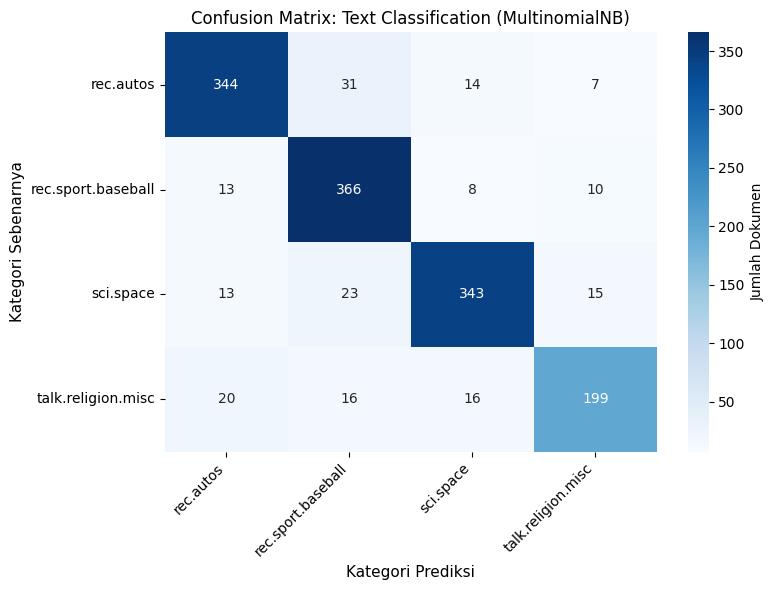

Classification Report:


,precision,recall,f1-score,support
rec.autos,0.882,0.869,0.875,396
rec.sport.baseball,0.839,0.922,0.879,397
sci.space,0.900,0.871,0.885,394
talk.religion.misc,0.861,0.793,0.826,251
accuracy,0.871,0.871,0.871,1
macro avg,0.871,0.863,0.866,1438
weighted avg,0.872,0.871,0.870,1438


In [7]:
# Evaluasi Performa dengan Confusion Matrix Heatmap
cm_text = confusion_matrix(y_test_text, y_pred_text)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_text,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    cbar_kws={'label': 'Jumlah Dokumen'}
)
plt.title('Confusion Matrix: Text Classification (MultinomialNB)', fontsize=12)
plt.xlabel('Kategori Prediksi', fontsize=11)
plt.ylabel('Kategori Sebenarnya', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Laporan Klasifikasi Rinci
report_text = classification_report(y_test_text, y_pred_text, target_names=target_names, output_dict=True)
df_report_text = pd.DataFrame(report_text).transpose()
print("Classification Report:")
display(df_report_text.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format({
    'precision': '{:.3f}',
    'recall': '{:.3f}',
    'f1-score': '{:.3f}',
    'support': '{:.0f}'
}))

In [8]:
# Inferensi pada Contoh Kalimat Baru Tanpa Label
new_samples = [
    "The launch of the lunar satellite was successful and reached orbit.",
    "His batting average improved significantly during the championship season.",
    "Engine oil leaks can cause severe damage to the car transmission.",
    "The sermon discussed sacred scriptures, moral faith, and spiritual belief."
]

predicted_indices = text_clf_pipeline.predict(new_samples)

print("=== Pengujian Inferensi Data Teks Baru ===")
for text, pred_idx in zip(new_samples, predicted_indices):
    print(f"Teks    : \"{text}\"")
    print(f"Prediksi: {target_names[pred_idx]}\n")

=== Pengujian Inferensi Data Teks Baru ===
Teks    : "The launch of the lunar satellite was successful and reached orbit."
Prediksi: sci.space

Teks    : "His batting average improved significantly during the championship season."
Prediksi: rec.sport.baseball

Teks    : "Engine oil leaks can cause severe damage to the car transmission."
Prediksi: rec.autos

Teks    : "The sermon discussed sacred scriptures, moral faith, and spiritual belief."
Prediksi: talk.religion.misc



## 4. Analisis dan Kesimpulan
1. **Daya Reduksi Derau TF-IDF**: Pembobotan TF-IDF yang dikombinasikan dengan pembersihan kata umum (*stop words*) dan pembatasan frekuensi minimum (`min_df`) mampu menyaring ribuan token yang tidak relevan secara signifikan.
2. **Efektivitas Multinomial Naive Bayes**: Meskipun mengasumsikan independensi fitur yang sederhana, algoritma Naive Bayes terbukti sangat tangguh dan cepat dalam mengklasifikasikan dokumen multikelas berskala besar dengan representasi matriks renggang (*sparse matrix*).
3. **Kepraktisan Pipeline**: Integrasi tahapan vektorisasi dan estimasi pemodelan dalam objek `Pipeline` menyederhanakan alur kerja produksi, memastikan teks masukan mentah baru dapat diproses secara deterministik tanpa risiko inkonsistensi kosakata atau dimensi vektor.